# Module 13 — L'apprentissage multi-tâche en profondeur

> **Objectif** : aller au-delà de « un encodeur, plusieurs têtes, une somme pondérée de pertes » (module 8, section 4). On voit **pourquoi** le multi-tâche aide ou nuit (transfert positif, compétition pour la capacité, conflits de gradients), les **architectures** de partage (dur, souple, mélange d'experts, adaptateurs), les **méthodes d'équilibrage** (incertitude, GradNorm, DWA, PCGrad) avec leurs maths, et surtout comment **mesurer** honnêtement le transfert. Tout est démontré en NumPy sur un problème à trois tâches où l'on contrôle ce qui est partagé, puis traduit en PyTorch.

| | |
|---|---|
| **Durée estimée** | 3 h 30 |
| **Prérequis** | Modules 0, 7, 8 (section 4 surtout) |
| **Librairies** | `numpy`, `matplotlib` ; `torch`, `transformers` (section 8) |

**Plan**

1. Pourquoi le multi-tâche peut aider… ou nuire
2. Architectures de partage
3. Le point de vue des gradients : conflits et déséquilibres
4. Optimalité de Pareto : une illustration en 2D
5. Les méthodes d'équilibrage : incertitude, GradNorm, DWA, PCGrad
6. Expérience : trois tâches, transfert positif et négatif
7. Mesurer le transfert et choisir les groupes de tâches
8. En PyTorch : PCGrad, GradNorm, DWA, échantillonnage des tâches, MMoE
9. Protocole d'ablation pour un projet multi-tâche
10. Récapitulatif et exercices

In [1]:
import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)


class Adam:
    def __init__(self, params, lr=5e-3):
        self.p, self.lr = params, lr
        self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]; self.t = 0
    def step(self, grads):
        self.t += 1
        for p, g, m, v in zip(self.p, grads, self.m, self.v):
            m *= 0.9; m += 0.1 * g; v *= 0.999; v += 0.001 * g * g
            p -= self.lr * (m / (1 - 0.9 ** self.t)) / (np.sqrt(v / (1 - 0.999 ** self.t)) + 1e-8)

## 1. Pourquoi le multi-tâche peut aider… ou nuire

### 💡 Les mécanismes du transfert positif (Caruana, 1997 ; Ruder, 2017)

| Mécanisme | Idée |
|---|---|
| **Amplification des données** | une tâche peu annotée profite des représentations apprises grâce à une tâche riche en annotations |
| **Régularisation** | la représentation partagée doit servir plusieurs tâches : moins de sur-apprentissage sur chacune |
| **« Écoute indiscrète »** | une caractéristique difficile à apprendre pour la tâche A est facile pour B ; A en profite |
| **Biais de représentation** | on oriente l'encodeur vers des caractéristiques qui généralisent à plusieurs tâches |

### ⚠️ Les mécanismes du transfert négatif

| Mécanisme | Symptôme |
|---|---|
| **Compétition pour la capacité** | l'encodeur partagé est trop petit : ce qui est utile à une tâche est volé à une autre |
| **Déséquilibre d'échelle** | une perte (ou ses gradients) beaucoup plus grande domine l'optimisation |
| **Conflits de direction** | les gradients des tâches pointent dans des directions opposées sur les paramètres partagés |
| **Tâches non liées** | rien à partager, seulement du bruit ajouté |
| **Vitesses différentes** | une tâche converge (puis sur-apprend) pendant qu'une autre apprend encore |

Le multi-tâche n'est **pas** gratuit : la question à poser est toujours « **par rapport à quoi** ? ». La référence est le **modèle mono-tâche équivalent**, réglé avec le même soin.

## 2. Architectures de partage

```
 Partage dur                 Partage souple (cross-stitch)       Mélange d'experts (MMoE)
 ┌────┐ ┌────┐ ┌────┐        ┌────┐   ┌────┐                    ┌────┐ ┌────┐ ┌────┐
 │ A  │ │ B  │ │ C  │        │ A  │◄─►│ B  │   (colonnes par      │ A  │ │ B  │ │ C  │  têtes
 └─┬──┘ └─┬──┘ └─┬──┘        └─┬──┘   └─┬──┘    tâche, mélange    └─┬──┘ └─┬──┘ └─┬──┘
   └──────┼──────┘             │ ╲   ╱ │      appris entre        gateA gateB gateC   (une porte par tâche)
     encodeur partagé          │  ╳    │      couches)             └──┬────┬────┬──┘
                               │ ╱   ╲ │                          expert1 expert2 expert3
```

| Architecture | Principe | Quand |
|---|---|---|
| **Partage dur** | un encodeur commun, une tête par tâche | le défaut, le plus robuste ; fonctionne bien avec un grand Transformer pré-entraîné |
| **Hiérarchique** | les tâches « bas niveau » supervisent les couches basses, les tâches « haut niveau » les couches hautes (Søgaard & Goldberg, 2016) | tâches de niveaux d'abstraction différents (par exemple segments → type de séquence) |
| **Partage souple** (cross-stitch, Misra et al., 2016) | un réseau par tâche, combinaisons linéaires apprises entre leurs couches | peu de tâches, assez de calcul |
| **MMoE** (Ma et al., 2018) | des experts partagés, une **porte** par tâche choisit son mélange d'experts | tâches partiellement liées ; réduit la compétition |
| **Adaptateurs / LoRA par tâche** | un encodeur gelé ou partagé + de petits modules propres à chaque tâche (module 8) | beaucoup de tâches, limiter le transfert négatif |
| **Texte-vers-texte** (T5) | toutes les tâches formulées comme générer une chaîne, préfixe de tâche | grands modèles génératifs |

## 3. Le point de vue des gradients

### 📐 Deux tâches, des paramètres partagés $\theta$

Avec $\mathcal L = w_1\mathcal L_1 + w_2\mathcal L_2$, le pas de descente est $-\eta(w_1 g_1 + w_2 g_2)$ avec $g_i = \nabla_\theta\mathcal L_i$. Au premier ordre (module 0), l'effet de ce pas sur la tâche 1 est :
$$
\Delta\mathcal L_1 \approx -\eta\, g_1^\top(w_1 g_1 + w_2 g_2) = -\eta\big(w_1\lVert g_1\rVert^2 + w_2\, g_1^\top g_2\big)
$$
- si $g_1^\top g_2 > 0$ (gradients **alignés**), chaque tâche aide l'autre ;
- si $g_1^\top g_2 < 0$ (gradients en **conflit**) et que $w_2\lVert g_2\rVert$ est grand devant $w_1\lVert g_1\rVert$, le pas peut **augmenter** $\mathcal L_1$ : la tâche 2 « tire » la tâche 1 en arrière.

Deux pathologies distinctes, que les méthodes de la section 5 attaquent séparément :
- **déséquilibre de magnitude** ($\lVert g_2\rVert\gg\lVert g_1\rVert$) : corrigé par les **poids** (incertitude, GradNorm, DWA) ;
- **conflit de direction** ($\cos(g_1, g_2) < 0$) : corrigé par la **chirurgie de gradients** (PCGrad).

## 4. Optimalité de Pareto : une illustration en 2D

Avec plusieurs objectifs, il n'y a en général pas de solution qui minimise tout à la fois. Une solution est **Pareto-optimale** si on ne peut améliorer une tâche sans en dégrader une autre. L'ensemble de ces solutions est le **front de Pareto**. Une somme pondérée $\sum_i w_i\mathcal L_i$ mène à **un** point du front, différent selon les poids. Choisir des poids, c'est choisir un compromis.

Deux tâches quadratiques sur un paramètre $\theta\in\mathbb R^2$, avec des minima différents et des échelles très différentes :
$$
\mathcal L_1(\theta) = \lVert\theta - a\rVert^2,\qquad \mathcal L_2(\theta) = 10\,(\theta - b)^\top\Sigma\,(\theta - b)
$$

somme égale (w = 1, 1)       final L1 = 2.014 | L2 = 1.019
poids rééquilibrés (1, 0.1)  final L1 = 0.450 | L2 = 6.106
PCGrad                       final L1 = 1.633 | L2 = 1.480


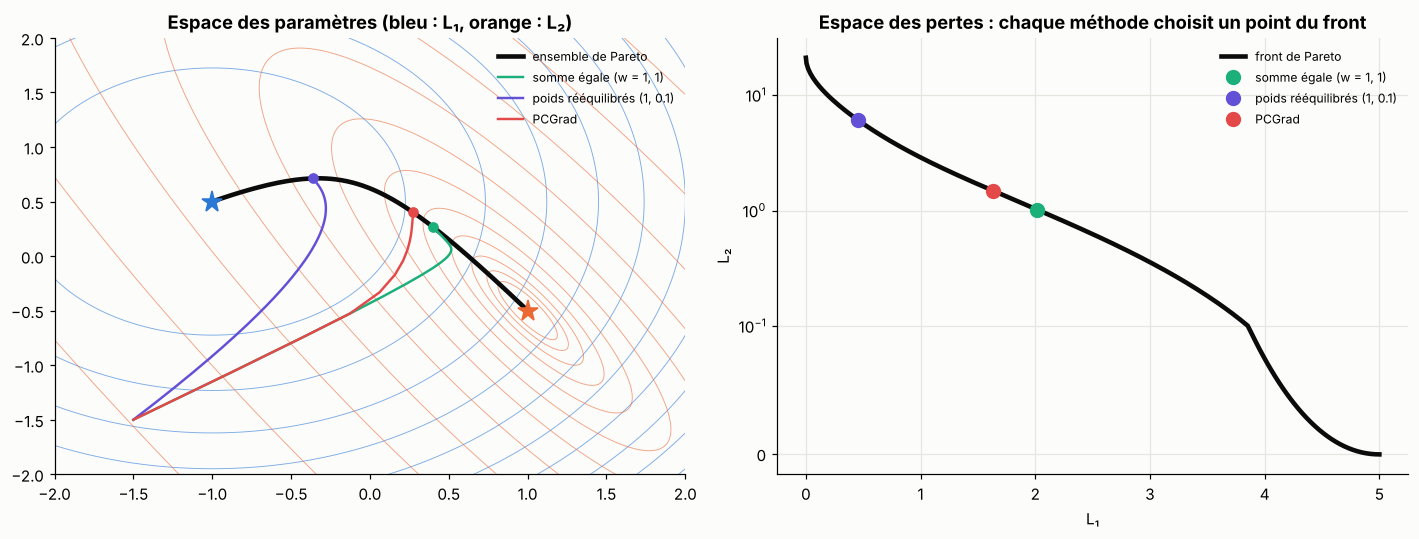

In [2]:
a_opt, b_opt = np.array([-1.0, 0.5]), np.array([1.0, -0.5])
Sig = np.array([[1.0, 0.6], [0.6, 0.5]])
L1 = lambda th: np.sum((th - a_opt) ** 2, -1)
L2 = lambda th: 10 * np.einsum("...i,ij,...j->...", th - b_opt, Sig, th - b_opt)
g1 = lambda th: 2 * (th - a_opt)
g2 = lambda th: 20 * (th - b_opt) @ Sig


def descend(update, steps=400, lr=0.01, start=(-1.5, -1.5)):
    th = np.array(start); path = [th.copy()]
    for _ in range(steps):
        th = th - lr * update(th); path.append(th.copy())
    return np.array(path)


def pcgrad_update(th):
    gs = [g1(th), g2(th)]
    out = []
    for i, j in [(0, 1), (1, 0)]:
        gi = gs[i].copy()
        if gi @ gs[j] < 0:
            gi -= (gi @ gs[j]) / (gs[j] @ gs[j]) * gs[j]           # remove the conflicting component
        out.append(gi)
    return out[0] + out[1]

# The Pareto set of two quadratics: minimizers of lam * L1 + (1 - lam) * L2 for lam in [0, 1]
lams = np.linspace(0, 1, 200)
pareto = np.array([np.linalg.solve(l * np.eye(2) + (1 - l) * 10 * Sig, l * a_opt + (1 - l) * 10 * Sig @ b_opt) for l in lams])

paths = {"somme égale (w = 1, 1)": descend(lambda th: g1(th) + g2(th)),
         "poids rééquilibrés (1, 0.1)": descend(lambda th: g1(th) + 0.1 * g2(th)),
         "PCGrad": descend(pcgrad_update)}

xx, yy = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-2, 2, 300))
grid = np.stack([xx, yy], -1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].contour(xx, yy, L1(grid), levels=12, colors=PALETTE[0], linewidths=0.6, alpha=0.6)
axes[0].contour(xx, yy, L2(grid), levels=np.logspace(-1, 2, 12), colors=PALETTE[1], linewidths=0.6, alpha=0.6)
axes[0].plot(pareto[:, 0], pareto[:, 1], color="#0b0b0b", lw=3, label="ensemble de Pareto")
for (name, p), c in zip(paths.items(), [PALETTE[2], PALETTE[6], PALETTE[7]]):
    axes[0].plot(p[:, 0], p[:, 1], color=c, lw=1.6, label=name); axes[0].plot(*p[-1], "o", color=c)
axes[0].plot(*a_opt, "*", ms=14, color=PALETTE[0]); axes[0].plot(*b_opt, "*", ms=14, color=PALETTE[1])
axes[0].set_title("Espace des paramètres (bleu : L₁, orange : L₂)"); axes[0].legend(fontsize=8, loc="upper right"); axes[0].grid(False)
axes[1].plot(L1(pareto), L2(pareto), color="#0b0b0b", lw=3, label="front de Pareto")
for (name, p), c in zip(paths.items(), [PALETTE[2], PALETTE[6], PALETTE[7]]):
    axes[1].plot(L1(p[-1]), L2(p[-1]), "o", ms=9, color=c, label=name)
axes[1].set_xlabel("L₁"); axes[1].set_ylabel("L₂"); axes[1].set_yscale("symlog", linthresh=0.1)
axes[1].set_title("Espace des pertes : chaque méthode choisit un point du front"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for name, p in paths.items():
    print(f"{name:28s} final L1 = {L1(p[-1]):.3f} | L2 = {L2(p[-1]):.3f}")

**Lecture** : toutes les méthodes finissent **sur** le front de Pareto, mais en des points différents. La somme égale est attirée vers le minimum de la tâche à grande échelle ($\mathcal L_2$, multipliée par 10). Rééquilibrer les poids déplace le compromis vers $\mathcal L_1$. PCGrad, qui ne retire que la composante conflictuelle, s'arrête dès qu'il atteint le front (les gradients deviennent exactement opposés et s'annulent après projection) : il **ne choisit pas** un meilleur compromis, il évite seulement de traverser des zones où une tâche se dégrade. **Aucune méthode ne dispense de décider quel compromis on veut.**

## 5. Les méthodes d'équilibrage

### 📐 Pondération par incertitude (Kendall et al., 2018)

Vue au module 8 : $\mathcal L = \sum_i \frac12 e^{-s_i}\mathcal L_i + \frac12 s_i$, et à l'optimum $e^{s_i} = \sigma_i^2 = \mathcal L_i$. Chaque tâche est pondérée par l'**inverse de sa perte courante** : corrige les écarts d'**échelle**.

### 📐 GradNorm (Chen et al., 2018)

Équilibre directement les **normes de gradient** sur la dernière couche partagée $W$. Avec $G_i = \lVert\nabla_W (w_i\mathcal L_i)\rVert$, $\bar G$ leur moyenne, et la vitesse d'apprentissage relative $r_i = \tilde{\mathcal L}_i/\mathbb E_j[\tilde{\mathcal L}_j]$ où $\tilde{\mathcal L}_i = \mathcal L_i(t)/\mathcal L_i(0)$ :
$$
\mathcal L_{\text{grad}}(w) = \sum_i\big|\,G_i(w) - \bar G\cdot r_i^{\ \alpha}\,\big|
$$
On met à jour les **poids** $w_i$ par descente sur $\mathcal L_{\text{grad}}$ (la cible $\bar G r_i^\alpha$ est traitée comme une constante), puis on renormalise $\sum_i w_i = K$. Une tâche **en retard** (grand $r_i$) reçoit un gradient plus fort. $\alpha$ (souvent 0,5–1,5) règle la force du rééquilibrage.

### 📐 DWA, *Dynamic Weight Average* (Liu et al., 2019)

Sans gradient supplémentaire, à partir des pertes des deux époques précédentes :
$$
w_i(t) = \frac{K\exp\big(\rho_i(t-1)/T\big)}{\sum_j\exp\big(\rho_j(t-1)/T\big)},\qquad \rho_i(t-1) = \frac{\mathcal L_i(t-1)}{\mathcal L_i(t-2)}
$$
Une tâche dont la perte baisse lentement ($\rho_i$ proche de 1) est sur-pondérée.

### 📐 PCGrad, la chirurgie de gradients (Yu et al., 2020)

Pour chaque tâche $i$ et chaque autre tâche $j$ (dans un ordre aléatoire), si $g_i^\top g_j < 0$, on retire de $g_i$ sa projection sur $g_j$ :
$$
g_i \leftarrow g_i - \frac{g_i^\top g_j}{\lVert g_j\rVert^2}\,g_j
$$
puis on somme les gradients modifiés. Les composantes conflictuelles disparaissent ; les composantes alignées sont conservées. Coût : un gradient **par tâche** sur les paramètres partagés (au lieu d'un seul).

> ⚠️ **L'état du débat** : plusieurs études soignées (Kurin et al., 2022, « In Defense of the Unitary Scalarization » ; Xin et al., 2022) trouvent que, **avec un réglage standard de régularisation** (dropout, weight decay, early stopping) et des poids raisonnables, la simple somme fait souvent aussi bien que ces méthodes. Leur intérêt réel dépend du problème : à tester, jamais à supposer.

## 6. Expérience : trois tâches, transfert positif et négatif

On construit un problème de régression dont on **contrôle** la structure :
- **tâche A** : dépend de caractéristiques latentes $f_U(x)$ ; **seulement 150 exemples annotés** ;
- **tâche B** : dépend des **mêmes** caractéristiques $f_U(x)$ (autre combinaison, avec une interaction) ; 2 400 exemples annotés. Elle devrait **aider** A ;
- **tâche C** : dépend de caractéristiques **différentes** $f_V(x)$, avec une **échelle 5 fois plus grande** et plus de bruit ; 2 400 exemples. Elle devrait **nuire** si la capacité partagée est limitée.

Modèle : $h = \tanh(Wx + b)$ partagé (largeur $H$), une tête linéaire par tâche. Les étiquettes manquantes (tâche A) sont masquées dans la perte, comme au module 8.

In [3]:
n, d = 3000, 12
U, V = rng.normal(size=(d, 3)), rng.normal(size=(d, 3))
X = rng.normal(size=(n, d))
fU, fV = np.tanh(X @ U / np.sqrt(d) * 2), np.tanh(X @ V / np.sqrt(d) * 2)
ca, cb, cc = rng.normal(size=3), rng.normal(size=3), rng.normal(size=3)
Y = np.stack([fU @ ca + 0.1 * rng.normal(size=n),
              fU @ cb + 0.5 * fU[:, 0] * fU[:, 1] + 0.1 * rng.normal(size=n),
              5 * (fV @ cc) + 0.5 * rng.normal(size=n)], axis=1)
TASKS = ["A", "B", "C"]
train_idx, test_idx = np.arange(2400), np.arange(2400, n)
has_label = np.zeros((n, 3), bool); has_label[:150, 0] = True; has_label[:2400, 1:] = True   # A: 150 labels only
print("label counts in train:", has_label[train_idx].sum(0), "| target std per task:", Y.std(0).round(2))


def run_mtl(tasks, method="equal", H=8, steps=3000, lr=5e-3, seed=0, log_grads=False):
    r = np.random.default_rng(seed)
    W = r.normal(0, 1 / np.sqrt(d), (d, H)); b = np.zeros(H)
    heads = [r.normal(0, 0.1, H) for _ in range(3)]; c0 = np.zeros(3); s = np.zeros(3)
    opt = Adam([W, b] + heads + [c0, s], lr)
    w = np.ones(3); L_init = None; loss_hist = []; grad_log = []
    for it in range(steps):
        idx = r.choice(train_idx, 256)
        Xb = X[idx]; Hh = np.tanh(Xb @ W + b)
        gW, gb, gh, gc, Ls = [], [], [np.zeros(H) for _ in range(3)], np.zeros(3), np.zeros(3)
        for t in range(3):
            m = has_label[idx, t]
            if t not in tasks or m.sum() == 0:
                gW.append(np.zeros_like(W)); gb.append(np.zeros(H)); continue
            e = (Hh @ heads[t] + c0[t] - Y[idx, t]) * m
            Ls[t] = (e ** 2).sum() / m.sum()
            de = 2 * e / m.sum()
            gh[t] = Hh.T @ de; gc[t] = de.sum()
            dZ = np.outer(de, heads[t]) * (1 - Hh ** 2)
            gW.append(Xb.T @ dZ); gb.append(dZ.sum(0))
        act = list(tasks)
        if log_grads and it % 50 == 0 and len(act) == 3:
            flat = [np.concatenate([gW[t].ravel(), gb[t]]) for t in range(3)]
            cos = lambda u, v: u @ v / (np.linalg.norm(u) * np.linalg.norm(v) + 1e-12)
            grad_log.append((it, cos(flat[0], flat[1]), cos(flat[0], flat[2]), cos(flat[1], flat[2]),
                             *[np.linalg.norm(f) for f in flat]))
        g_s = np.zeros(3)
        if method == "uncertainty":
            w = np.exp(-s)
            g_s = 0.5 * (1 - np.exp(-s) * Ls); g_s[[t for t in range(3) if t not in act]] = 0
        elif method == "dwa" and it % 100 == 0:
            loss_hist.append(Ls.copy())
            if len(loss_hist) >= 3:
                rho = loss_hist[-1][act] / np.maximum(loss_hist[-2][act], 1e-8)
                e_ = np.exp(rho / 2.0); w = np.ones(3); w[act] = len(act) * e_ / e_.sum()
        elif method == "gradnorm":
            if L_init is None:
                L_init = np.where(Ls > 0, Ls, 1.0)
            Gn = np.array([np.linalg.norm(gW[t]) for t in range(3)])
            Gi = w * Gn; ratio = Ls / L_init; r_rel = ratio / ratio[act].mean()
            target = Gi[act].mean() * r_rel ** 1.5
            g_w = np.sign(Gi - target) * Gn; g_w[[t for t in range(3) if t not in act]] = 0
            w = np.maximum(w - 0.01 * g_w, 0.01); w = w * len(act) / w[act].sum()
        if method == "pcgrad":
            flat = [np.concatenate([gW[t].ravel(), gb[t]]) for t in range(3)]
            proj = [f.copy() for f in flat]
            for i in act:
                for j in r.permutation(act):
                    if i != j and proj[i] @ flat[j] < 0:
                        proj[i] -= (proj[i] @ flat[j]) / (flat[j] @ flat[j] + 1e-12) * flat[j]
            tot = sum(proj[t] for t in act)
            GW, Gb = tot[:W.size].reshape(W.shape), tot[W.size:]
            head_w = np.ones(3)
        else:
            GW, Gb = sum(w[t] * gW[t] for t in act), sum(w[t] * gb[t] for t in act)
            head_w = w
        opt.step([GW, Gb] + [head_w[t] * gh[t] for t in range(3)] + [head_w * gc, g_s])
    Ht = np.tanh(X[test_idx] @ W + b)
    rmse = np.array([np.sqrt(np.mean((Ht @ heads[t] + c0[t] - Y[test_idx, t]) ** 2)) if t in tasks else np.nan for t in range(3)])
    return rmse, np.array(grad_log)

label counts in train: [ 150 2400 2400] | target std per task: [1.7  0.49 5.27]


In [4]:
configs = [("mono-tâche A", [0], "equal"), ("mono-tâche B", [1], "equal"), ("mono-tâche C", [2], "equal"),
           ("A+B (somme)", [0, 1], "equal"),
           ("A+B+C somme", [0, 1, 2], "equal"), ("A+B+C incertitude", [0, 1, 2], "uncertainty"),
           ("A+B+C GradNorm", [0, 1, 2], "gradnorm"), ("A+B+C DWA", [0, 1, 2], "dwa"), ("A+B+C PCGrad", [0, 1, 2], "pcgrad")]
seeds = [0, 1, 2]
table = {}
for H in [8, 32]:
    for name, tasks, meth in configs:
        runs = np.array([run_mtl(tasks, meth, H=H, seed=sd)[0] for sd in seeds])
        table[(H, name)] = (runs.mean(0), runs.std(0))       # NaN for tasks not trained
    print(f"\n=== shared width H = {H} (test RMSE, mean over {len(seeds)} seeds; lower is better) ===")
    print(f"{'':22s}" + "".join(f"{t:>14s}" for t in TASKS))
    for name, _, _ in configs:
        m, sd = table[(H, name)]
        print(f"{name:22s}" + "".join(f"{'—':>14s}" if np.isnan(v) else f"{v:9.3f} ±{e:.3f}" for v, e in zip(m, sd)))


=== shared width H = 8 (test RMSE, mean over 3 seeds; lower is better) ===
                                   A             B             C
mono-tâche A              0.203 ±0.016             —             —
mono-tâche B                       —    0.113 ±0.002             —
mono-tâche C                       —             —    0.529 ±0.003
A+B (somme)               0.146 ±0.003    0.139 ±0.022             —
A+B+C somme               0.389 ±0.018    0.297 ±0.034    0.530 ±0.003
A+B+C incertitude         0.149 ±0.002    0.269 ±0.003    0.523 ±0.003
A+B+C GradNorm            0.374 ±0.002    0.164 ±0.013    0.740 ±0.033
A+B+C DWA                 0.383 ±0.024    0.294 ±0.032    0.532 ±0.003
A+B+C PCGrad              0.383 ±0.007    0.293 ±0.028    0.535 ±0.004

=== shared width H = 32 (test RMSE, mean over 3 seeds; lower is better) ===
                                   A             B             C
mono-tâche A              0.252 ±0.012             —             —
mono-tâche B             

### Mesurer le transfert : $\Delta_{\text{MTL}}$

La métrique standard (Maninis et al., 2019) est l'amélioration relative **moyenne** par rapport aux modèles mono-tâche, avec le bon signe selon que la métrique se minimise ou se maximise :
$$
\Delta_{\text{MTL}} = \frac{1}{K}\sum_{i=1}^{K}(-1)^{\ell_i}\,\frac{M_{\text{MTL},i} - M_{\text{STL},i}}{M_{\text{STL},i}}
$$
($\ell_i = 1$ si une valeur plus basse est meilleure, comme une RMSE.) $\Delta_{\text{MTL}} > 0$ : le multi-tâche aide en moyenne. Toujours rapporter aussi le détail **par tâche**, car une moyenne peut cacher une tâche sacrifiée.

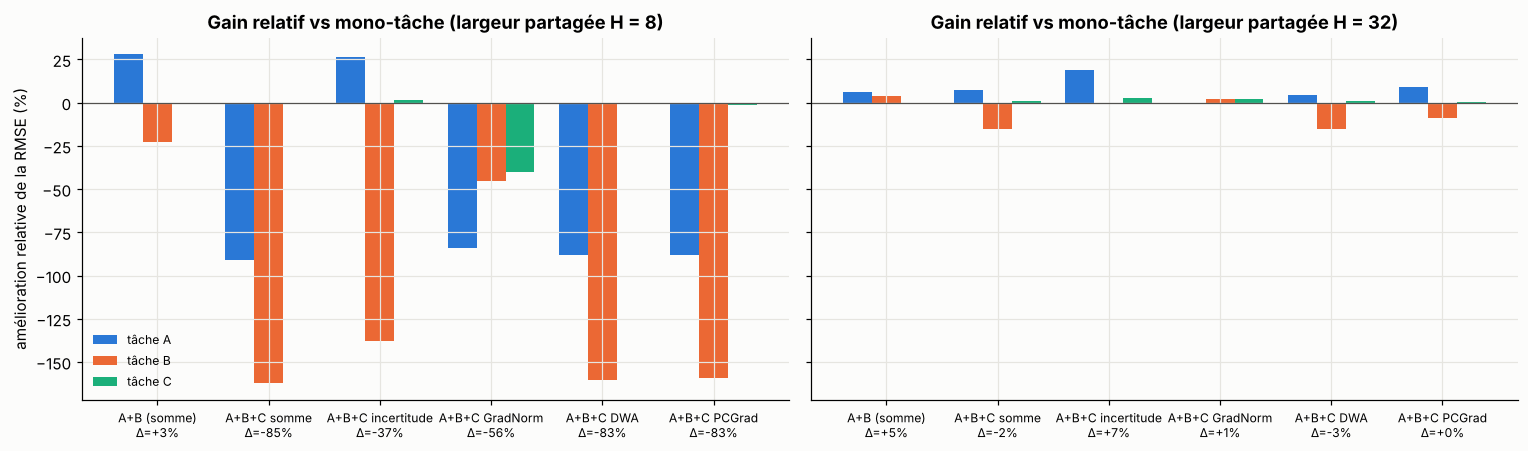

In [5]:
def delta_mtl(H, name):
    stl = np.array([table[(H, f"mono-tâche {t}")][0][i] for i, t in enumerate(TASKS)])
    mtl = table[(H, name)][0]
    valid = ~np.isnan(mtl)
    return np.mean(-(mtl[valid] - stl[valid]) / stl[valid]) * 100, -(mtl - stl) / stl * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
mtl_names = [c[0] for c in configs[3:]]
for ax, H in zip(axes, [8, 32]):
    per_task = np.array([delta_mtl(H, nm)[1] for nm in mtl_names])
    x = np.arange(len(mtl_names))
    for k, (t, c) in enumerate(zip(TASKS, PALETTE)):
        ax.bar(x + (k - 1) * 0.26, per_task[:, k], 0.26, color=c, label=f"tâche {t}")
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([f"{nm}\nΔ={delta_mtl(H, nm)[0]:+.0f}%" for nm in mtl_names], fontsize=8)
    ax.set_title(f"Gain relatif vs mono-tâche (largeur partagée H = {H})")
axes[0].set_ylabel("amélioration relative de la RMSE (%)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

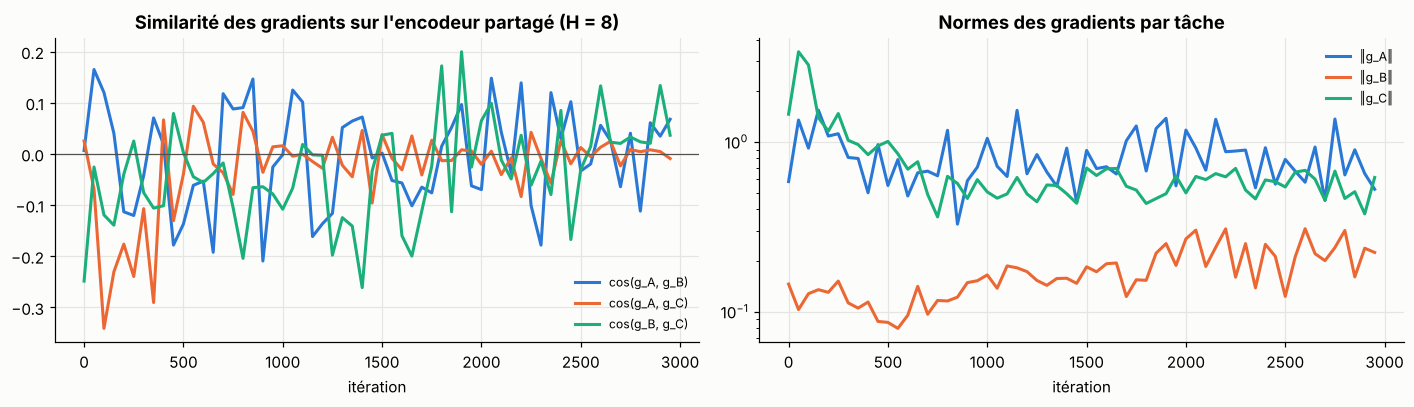

In [6]:
_, glog = run_mtl([0, 1, 2], "equal", H=8, seed=0, log_grads=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(glog[:, 0], glog[:, 1], label="cos(g_A, g_B)")
axes[0].plot(glog[:, 0], glog[:, 2], label="cos(g_A, g_C)")
axes[0].plot(glog[:, 0], glog[:, 3], label="cos(g_B, g_C)")
axes[0].axhline(0, color="#52514e", lw=0.8); axes[0].set_title("Similarité des gradients sur l'encodeur partagé (H = 8)")
axes[0].set_xlabel("itération"); axes[0].legend(fontsize=8)
for k, (t, c) in enumerate(zip(TASKS, PALETTE)):
    axes[1].semilogy(glog[:, 0], glog[:, 4 + k], color=c, label=f"‖g_{t}‖")
axes[1].set_title("Normes des gradients par tâche"); axes[1].set_xlabel("itération"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture critique** (à vérifier sur tes sorties : les chiffres exacts varient avec les graines) :
- **A+B** : avec une petite capacité partagée, la tâche A (150 étiquettes) profite nettement de B : c'est l'**amplification des données**. B, elle, peut perdre un peu : même le « bon » transfert n'est pas forcément symétrique.
- **A+B+C, somme simple, H = 8** : C, d'échelle 5 fois plus grande et sans rapport avec A et B, **dégrade fortement** les deux autres : transfert **négatif** massif. Les diagnostics de gradients sont instructifs. Les cosinus oscillent autour de 0 : il n'y a **pas** de conflit de direction systématique. Les normes de $g_A$ et $g_C$ sont comparables (celle de $g_A$ est grande et bruitée car chaque batch ne contient qu'une dizaine d'exemples annotés pour A), mais $\lVert g_B\rVert$ est environ 5 fois plus faible : B est **noyée**, et c'est la tâche la plus dégradée. Le cœur du problème est la **compétition pour 8 neurones partagés** entre des tâches dont les pertes ont des échelles très différentes (la MSE résiduelle de C est 10 à 20 fois celle de A ou B).
- **Les remèdes ne sont pas interchangeables** : la pondération par incertitude, qui corrige l'échelle, rend à A l'essentiel de son gain ; **PCGrad ne change presque rien**, ce qui est cohérent avec le diagnostic (il corrige des conflits de direction, absents ici). GradNorm et DWA donnent des compromis différents, parfois en sacrifiant une autre tâche.
- **Avec H = 32**, la compétition pour la capacité disparaît en grande partie, et le transfert négatif aussi. Mais le modèle mono-tâche A sur-apprend davantage avec ses 150 exemples. Leçon : le transfert dépend de la **capacité**, et une conclusion « la tâche C nuit » obtenue sur un petit modèle peut ne pas tenir sur un grand (et inversement).

## 7. Mesurer le transfert et choisir les groupes de tâches

Avec $K$ tâches, il y a $2^K - 1$ groupes possibles : on ne peut pas tout entraîner. Stratégies :

1. **Matrice de transfert par paires** : entraîner chaque paire $(i, j)$ et mesurer le gain de $i$ quand on ajoute $j$. Coût $O(K^2)$ entraînements. Le transfert n'est **pas symétrique** et n'est **pas additif** (deux tâches qui aident séparément peuvent se gêner ensemble).
2. **Affinité par « regard en avant »** (*Task Affinity Grouping*, Fifty et al., 2021) : pendant **un seul** entraînement commun, on mesure à intervalles réguliers de combien un pas de gradient de la tâche $j$ sur l'encodeur partagé change la perte de la tâche $i$ :
$$
Z_{j\to i} = 1 - \frac{\mathcal L_i\big(\theta_s - \eta\nabla_{\theta_s}\mathcal L_j\big)}{\mathcal L_i(\theta_s)}
$$
$Z_{j\to i} > 0$ : la tâche $j$ aide $i$. On regroupe ensuite les tâches qui s'aident mutuellement.
3. **Similarité des gradients** (cosinus, section 6) : bon marché, mais ne voit que les directions, pas les magnitudes.

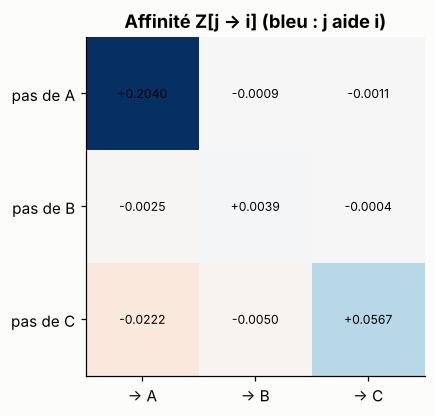

In [7]:
def lookahead_affinity(H=8, steps=1500, eta=0.05, seed=0):
    """Train A+B+C jointly (uncertainty weights) and accumulate Z[j -> i] with a one-step lookahead on the shared layer."""
    r = np.random.default_rng(seed)
    W = r.normal(0, 1 / np.sqrt(d), (d, H)); b = np.zeros(H); heads = [r.normal(0, 0.1, H) for _ in range(3)]; c0 = np.zeros(3)
    s = np.zeros(3); opt = Adam([W, b] + heads + [c0, s], 5e-3)
    Z = np.zeros((3, 3)); count = 0

    def task_losses_and_grads(Wc, bc, idx):
        Hh = np.tanh(X[idx] @ Wc + bc); Ls, gW, gb, gh, gc = np.zeros(3), [], [], [], np.zeros(3)
        for t in range(3):
            m = has_label[idx, t]
            e = (Hh @ heads[t] + c0[t] - Y[idx, t]) * m; Ls[t] = (e ** 2).sum() / max(1, m.sum())
            de = 2 * e / max(1, m.sum()); gh.append(Hh.T @ de); gc[t] = de.sum()
            dZ = np.outer(de, heads[t]) * (1 - Hh ** 2); gW.append(X[idx].T @ dZ); gb.append(dZ.sum(0))
        return Ls, gW, gb, gh, gc

    for it in range(steps):
        idx = r.choice(train_idx, 256)
        Ls, gW, gb, gh, gc = task_losses_and_grads(W, b, idx)
        if it % 25 == 0 and it > 200:
            for j in range(3):
                Ls_ahead = task_losses_and_grads(W - eta * gW[j], b - eta * gb[j], idx)[0]
                Z[j] += 1 - Ls_ahead / np.maximum(Ls, 1e-12)
            count += 1
        w = np.exp(-s)
        opt.step([sum(w[t] * gW[t] for t in range(3)), sum(w[t] * gb[t] for t in range(3))]
                 + [w[t] * gh[t] for t in range(3)] + [w * gc, 0.5 * (1 - np.exp(-s) * Ls)])
    return Z / count

Zaff = lookahead_affinity()
fig, ax = plt.subplots(figsize=(4.6, 4))
vmax = np.abs(Zaff).max()
ax.imshow(Zaff, cmap="RdBu", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(3)); ax.set_xticklabels([f"→ {t}" for t in TASKS]); ax.set_yticks(range(3)); ax.set_yticklabels([f"pas de {t}" for t in TASKS])
for (i, j), v in np.ndenumerate(Zaff):
    ax.text(j, i, f"{v:+.4f}", ha="center", va="center", fontsize=8)
ax.set_title("Affinité Z[j → i] (bleu : j aide i)"); ax.grid(False)
plt.show()

La diagonale (une tâche s'aide elle-même) est évidemment positive ; ce qui nous intéresse, ce sont les cases hors diagonale.

**Lecture critique** : l'affinité détecte bien que **C nuit à A** (case négative la plus forte). En revanche, elle ne voit **pas** que B aide A, alors que l'expérience de la section 6 montre un gain net. Le bénéfice de B pour A est une **régularisation** qui se manifeste sur la **généralisation** (erreur de test, avec seulement 150 exemples de A), pas sur la perte d'entraînement du batch courant, qui est ce que mesure le regard en avant à un pas. C'est une limite réelle de ces mesures bon marché : elles proposent des groupes candidats, que seuls de vrais entraînements évalués sur la validation permettent de confirmer.

## 8. En PyTorch

### 8.1 PCGrad sur les paramètres partagés

In [ ]:
import random
import torch
import torch.nn as nn
import torch.nn.functional as F


def pcgrad_backward(losses, shared_params, task_specific_params=()):
    """Compute per-task gradients on the shared parameters, project out conflicts, write the result into .grad."""
    shared_params = [p for p in shared_params if p.requires_grad]
    grads = []
    for L in losses:
        g = torch.autograd.grad(L, shared_params, retain_graph=True, allow_unused=True)
        grads.append(torch.cat([(gi if gi is not None else torch.zeros_like(p)).flatten() for gi, p in zip(g, shared_params)]))
    projected = [g.clone() for g in grads]
    for i in range(len(grads)):
        order = list(range(len(grads))); random.shuffle(order)
        for j in order:
            if i != j:
                dot = projected[i] @ grads[j]
                if dot < 0:
                    projected[i] -= dot / (grads[j].norm() ** 2 + 1e-12) * grads[j]
    total = torch.stack(projected).sum(0)
    offset = 0
    for p in shared_params:
        p.grad = total[offset:offset + p.numel()].view_as(p).clone(); offset += p.numel()
    # task-specific parameters: ordinary backward of the summed loss (their gradients never conflict)
    if task_specific_params:
        tsum = torch.autograd.grad(sum(losses), list(task_specific_params), allow_unused=True)
        for p, g in zip(task_specific_params, tsum):
            p.grad = g


# usage inside a training step:
# opt.zero_grad(); losses = [loss_token, loss_seq]
# pcgrad_backward(losses, model.encoder.parameters(), list(model.token_head.parameters()) + list(model.seq_head.parameters()))
# opt.step()

> ⚠️ Avec un Transformer, les paramètres partagés se comptent en centaines de millions : stocker un gradient aplati **par tâche** coûte cher en mémoire. Variantes pratiques : appliquer PCGrad sur la dernière couche partagée seulement, ou sur un sous-ensemble de paramètres.

### 8.2 GradNorm et DWA

In [ ]:
class GradNorm:
    """Learns task weights so that ||grad_W (w_i L_i)|| follows the relative training rate (Chen et al., 2018)."""

    def __init__(self, n_tasks, alpha=1.5, lr=0.025):
        self.w = torch.ones(n_tasks, requires_grad=True)
        self.opt = torch.optim.Adam([self.w], lr=lr)
        self.alpha, self.L0 = alpha, None

    def weighted_loss_and_update(self, losses, last_shared_weight):
        L = torch.stack(losses)
        if self.L0 is None:
            self.L0 = L.detach()
        G = torch.stack([torch.autograd.grad(self.w[i] * L[i], last_shared_weight, retain_graph=True, create_graph=True)[0].norm()
                         for i in range(len(losses))])
        ratio = (L.detach() / self.L0)
        target = (G.mean() * (ratio / ratio.mean()) ** self.alpha).detach()
        gn_loss = (G - target).abs().sum()
        self.opt.zero_grad(); gn_loss.backward(retain_graph=True); self.opt.step()
        with torch.no_grad():                                                   # renormalize: sum w = K
            self.w.clamp_(min=1e-3); self.w.mul_(len(losses) / self.w.sum())
        return (self.w.detach() * L).sum()                                      # use this for the model update


def dwa_weights(history, T=2.0):
    """history: list of per-epoch loss vectors (numpy). Returns weights for the next epoch."""
    K = len(history[-1])
    if len(history) < 2:
        return np.ones(K)
    rho = np.asarray(history[-1]) / np.maximum(np.asarray(history[-2]), 1e-8)
    e = np.exp(rho / T)
    return K * e / e.sum()

> 💡 Avec `GradNorm`, l'appel `gn_loss.backward()` accumule aussi des gradients dans les paramètres du modèle : appelle `model.zero_grad()` **après** `weighted_loss_and_update` et **avant** `loss.backward()` de la mise à jour du modèle.

### 8.3 Échantillonner les tâches quand elles viennent de jeux différents

In [8]:
class TaskSampler:
    """Draw task i with probability proportional to n_i ** (1 / T): T=1 proportional, T -> inf uniform."""

    def __init__(self, loaders: dict, T=2.0, seed=0):
        self.loaders = loaders
        self.iters = {k: iter(v) for k, v in loaders.items()}
        sizes = np.array([len(v.dataset) for v in loaders.values()], dtype=float)
        p = sizes ** (1 / T)
        self.p, self.names = p / p.sum(), list(loaders)
        self.rng = np.random.default_rng(seed)

    def next(self):
        task = self.names[self.rng.choice(len(self.names), p=self.p)]
        try:
            batch = next(self.iters[task])
        except StopIteration:                                    # restart an exhausted task loader
            self.iters[task] = iter(self.loaders[task]); batch = next(self.iters[task])
        return task, batch

### 8.4 MMoE : un mélange d'experts par tâche

In [ ]:
class MMoE(nn.Module):
    """Multi-gate Mixture-of-Experts on top of pooled encoder features (Ma et al., 2018)."""

    def __init__(self, d_in, n_experts=4, d_expert=128, task_out_dims=(4, 2)):
        super().__init__()
        self.experts = nn.ModuleList([nn.Sequential(nn.Linear(d_in, d_expert), nn.GELU()) for _ in range(n_experts)])
        self.gates = nn.ModuleList([nn.Linear(d_in, n_experts) for _ in task_out_dims])
        self.towers = nn.ModuleList([nn.Linear(d_expert, k) for k in task_out_dims])

    def forward(self, h):                                        # h: (B, d_in)
        E = torch.stack([e(h) for e in self.experts], dim=1)     # (B, n_experts, d_expert)
        outs = []
        for gate, tower in zip(self.gates, self.towers):
            g = torch.softmax(gate(h), dim=-1).unsqueeze(-1)     # (B, n_experts, 1): task-specific mixture
            outs.append(tower((g * E).sum(1)))
        return outs

mmoe = MMoE(d_in=768)
print([o.shape for o in mmoe(torch.randn(5, 768))])

## 9. Protocole d'ablation pour un projet multi-tâche

Pour un projet avec, par exemple, une tâche d'étiquetage de régions (par token) et plusieurs tâches de séquence (type, gène, espèce…) :

**Baselines obligatoires**
- [ ] un modèle **mono-tâche par tâche**, avec le même encodeur, le même budget d'entraînement et le même réglage d'hyperparamètres ;
- [ ] multi-tâche **somme simple** (après normalisation des pertes à une échelle comparable, par exemple en divisant chaque perte par sa valeur initiale).

**Variantes à comparer**
- [ ] pondération : somme / incertitude / (éventuellement) GradNorm ou DWA ;
- [ ] PCGrad uniquement si l'on **observe** des cosinus de gradients négatifs ;
- [ ] groupes de tâches (toutes ensemble vs groupes guidés par l'affinité) ;
- [ ] capacité : taille de l'encodeur partagé, têtes plus profondes, adaptateurs par tâche.

**Mesures**
- [ ] métriques **par tâche** + $\Delta_{\text{MTL}}$ ; jamais seulement une moyenne ;
- [ ] 3 à 5 graines ; IC bootstrap (module 8) ;
- [ ] courbes d'apprentissage par tâche (une tâche peut sur-apprendre pendant qu'une autre apprend : early stopping **par tâche** sur la validation, en gardant le meilleur checkpoint pour chacune si nécessaire) ;
- [ ] journaliser les poids appris ($\sigma_i$, $w_i$) et les normes / cosinus de gradients : ce sont des résultats qui expliquent les gains.

**Questions à trancher explicitement dans l'article**
- Le gain vient-il du multi-tâche ou simplement de **plus de données** vues par l'encodeur ? (Comparer à un pré-entraînement séquentiel : tâche B puis tâche A.)
- Le gain tient-il quand on **augmente la capacité** ?
- Quelles tâches **se nuisent** ? Une tâche sacrifiée est un résultat à rapporter, pas à cacher.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Transfert positif | amplification des données, régularisation, caractéristiques partagées |
| Transfert négatif | capacité, échelle, conflits de direction, tâches non liées |
| Architectures | partage dur (défaut), hiérarchique, souple, MMoE, adaptateurs par tâche |
| Gradients | $\Delta\mathcal L_1\approx-\eta(w_1\lVert g_1\rVert^2 + w_2 g_1^\top g_2)$ |
| Pareto | une somme pondérée choisit un point du front ; aucune méthode ne choisit le compromis à ta place |
| Incertitude | corrige l'**échelle** ; $\sigma_i^2\to\mathcal L_i$ |
| GradNorm | égalise les normes de gradient selon la vitesse relative d'apprentissage |
| DWA | sur-pondère les tâches dont la perte baisse lentement |
| PCGrad | retire les composantes de gradient **conflictuelles** ; inutile sans conflit |
| Mesure | $\Delta_{\text{MTL}}$ + détail par tâche ; matrice de transfert ; affinité par regard en avant |
| Débat | une somme bien réglée et régularisée est une baseline redoutable |

### 🏋️ Exercices

1. **Normaliser les pertes.** Divise chaque perte par sa valeur à l'initialisation (ou par la variance de la cible) et refais l'expérience à somme simple. Combien de l'écart avec la pondération par incertitude disparaît-il ?
2. **Créer un vrai conflit.** Ajoute une tâche D telle que $y_D = -y_A$ + bruit, sur les mêmes exemples. Mesure les cosinus de gradients et compare somme, incertitude et PCGrad. Dans quel cas PCGrad devient-il utile ?
3. **Têtes plus profondes.** Remplace les têtes linéaires par des têtes à une couche cachée. Le transfert négatif de C diminue-t-il à H = 8 ?
4. **Séquentiel vs joint.** Entraîne l'encodeur sur B seul, puis affine sur A seul. Compare à A+B joint. Quelle conclusion pour l'interprétation d'un gain multi-tâche ?
5. **Transfert asymétrique.** Calcule la matrice de transfert par paires (6 entraînements) et compare-la à l'affinité par regard en avant. Sont-elles cohérentes ?

<details><summary>Indications</summary>

1. Une grande partie du gain des méthodes adaptatives vient souvent du simple fait de **mettre les pertes à la même échelle**.
2. Avec des cibles opposées sur une capacité partagée limitée, les cosinus deviennent fortement négatifs : c'est le régime pour lequel PCGrad a été conçu.
4. Si le séquentiel fait aussi bien, le gain vient de la représentation apprise sur B, pas de l'entraînement conjoint en lui-même.
</details>

---

**Fin des modules avancés.** Avec les modules 10 à 13, tu disposes des briques méthodologiques d'un système d'annotation de séquences moderne : un encodeur pré-entraîné et adapté (modules 7–9), une tête d'étiquetage structurée (CRF, module 10), des représentations de séquences apprises par contraste (module 11), un modèle compressé ou entraîné à partir d'un outil existant (module 12), et un entraînement multi-tâche mesuré honnêtement (modules 8 et 13).